# 03 – Describe the data (tasks 13, 14, 15)


Before we build models, this notebook answers four questions:
1. **What do we learn from?** How is the heating index spread among the declared houses? (task 15)
2. **Who is the model for?** Which houses have not declared yet? (task 13)
3. **Are they alike?** Do the undeclared houses look like the declared ones? (task 14)
4. **What does this mean for our results?**

The test set has to stay unseen until the very end, so that the final result stays honest. This notebook therefore runs after `02_split_pipeline.ipynb` and uses only the cross-validation data.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from config import RAW, TABLES, FIGURES, THRESHOLD, load_cv

cv = load_cv()                                                    # declared buildings, without test set
status = pd.read_csv(RAW / "OCEN_ETAT_IDC_PUBLIC.csv", sep=";", encoding="utf-8-sig", low_memory=False)
reg = pd.read_csv(RAW / "gebaeude_batiment_edificio.csv", sep="\t", low_memory=False)
codes = pd.read_csv(RAW / "kodes_codes_codici.csv", sep="\t")

HOUSE_CLASSES = [1110, 1121]                                      # house = 1 or 2 dwellings
cv["above"] = cv["y"] > THRESHOLD                                 # True = above 450

def era_of(period):                                               # group 13 periods into 4 eras
    if period in ["Vor 1919", "1919-1945"]:
        return "before 1946"
    if period in ["1946-1960", "1961-1970", "1971-1980"]:
        return "1946-1980"
    if period in ["1981-1985", "1986-1990", "1991-1995", "1996-2000"]:
        return "1981-2000"
    if period in ["2001-2005", "2006-2010", "2011-2015", "Nach 2015"]:
        return "after 2000"
    return "unknown"

cv["era"] = cv["construction_period"].map(era_of)
houses = cv[cv["house"]]

What it does: loads the cross-validation data and the three raw files and the shared settings, marks buildings above 450, and groups the construction periods into 4 eras.

## 1. What do we learn from?
Key numbers and a histogram of the heating index of the declared houses. 


Above 450, all buildings: 29.0 %
Above 450, houses:        38.0 %
Median, all buildings: 390.0 | houses: 417.0


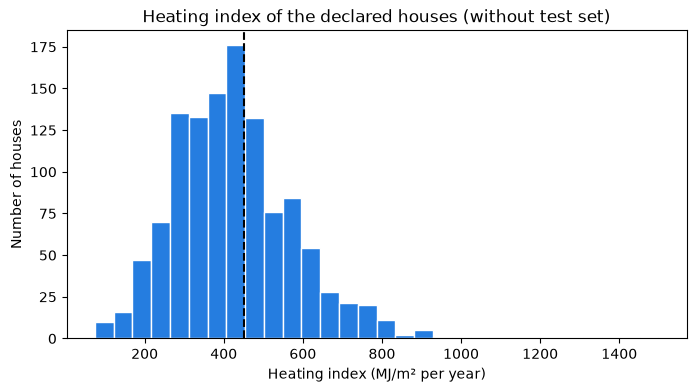

In [2]:
print("Above 450, all buildings:", round(cv["above"].mean() * 100, 1), "%")
print("Above 450, houses:       ", round(houses["above"].mean() * 100, 1), "%")
print("Median, all buildings:", cv["y"].median(), "| houses:", houses["y"].median())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(houses["y"], bins=30, color="#257de0", edgecolor="white")
ax.axvline(THRESHOLD, color="black", linestyle="--")
ax.set_xlabel("Heating index (MJ/m² per year)")
ax.set_ylabel("Number of houses")
ax.set_title("Heating index of the declared houses (without test set)")
fig.savefig(FIGURES / "describe_histogram_houses.png", dpi=150)
plt.show()

Result: 29% of all buildings and 38% of houses are above 450. Median: 390 for all buildings, 417 for houses.

## 2. Does the heating index differ between building types?
For example, do houses use more energy per m² than apartment blocks or offices?


In [3]:
by_class = cv.groupby("building_class").agg(buildings=("y", "size"), median=("y", "median"), above_450=("above", "mean"))
by_class["above_450"] = (by_class["above_450"] * 100).round(1)
print(by_class[by_class["buildings"] >= 100].sort_values("median", ascending=False))

                          buildings  median  above_450
building_class                                        
Gebäude mit 2 Wohnungen         333   422.0       40.2
Wohngeb.f.Gemeinschaften        100   419.0       41.0
Behälter, Silo, Lager           102   418.0       45.1
Gebäude mit 1 Wohnung           838   415.0       37.1
Gebäude mit 3+ Whgen           9416   393.0       27.9
Kultur-/Freizeitstätte          103   390.0       35.9
Gross- und Einzelhandel         184   364.0       32.1
Industriegebäude                287   347.0       26.8
Schul-/Hochschulgebäude         332   328.0       19.6
Bürogebäude                     556   321.0       19.2


Houses are among the building types with the highest heating index (median 415–422, 37–40% above 450). Small buildings have a lot of outer wall and roof per m² of living space, so they lose more heat. Houses are also the group that does not have to declare, which is why they matter most for the office.
Apartment blocks dominate the data: 9,416 of 12,710 buildings, against only 1,171 houses. If models were judged on all buildings, the apartment blocks would decide the result. That is why we judge models on houses (the lecturer's feedback point 1).
Houses are harder to predict: their median (415–422) lies just below the 450 line, so many houses are close to it, and their values are spread more widely than those of other buildings (standard deviation 152 vs. 123). This is why the task is not easy.

## 3. By construction era (houses)

Do older houses use more energy than newer ones? This section looks only at houses and groups them into 4 construction eras.

             houses  median  above_450
era                                   
before 1946     310   444.5       48.4
1946-1980       327   446.0       48.6
1981-2000       286   400.5       31.5
after 2000      248   343.0       18.5


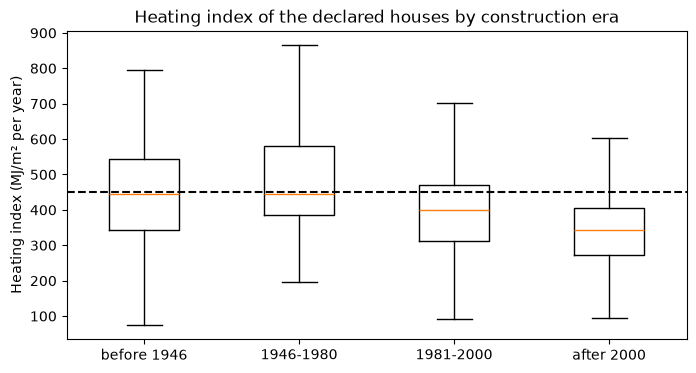

In [4]:
by_era = houses.groupby("era").agg(houses=("y", "size"), median=("y", "median"), above_450=("above", "mean"))
by_era["above_450"] = (by_era["above_450"] * 100).round(1)
by_era = by_era.reindex(["before 1946", "1946-1980", "1981-2000", "after 2000"])   # time order
print(by_era)

fig, ax = plt.subplots(figsize=(8, 4))
eras = ["before 1946", "1946-1980", "1981-2000", "after 2000"]
ax.boxplot([houses.loc[houses["era"] == e, "y"] for e in eras], showfliers=False)
ax.set_xticks(range(1, 5), eras)
ax.axhline(THRESHOLD, color="black", linestyle="--")
ax.set_ylabel("Heating index (MJ/m² per year)")
ax.set_title("Heating index of the declared houses by construction era")
fig.savefig(FIGURES / "describe_houses_by_era.png", dpi=150)
plt.show()

Age matters a lot. Almost half of the houses built before 1981 are problem houses. Among houses built after 2000, it's only about 1 in 5. Why around 1980? Building insulation standards in Switzerland became much stricter from the late 1970s and 1980s on (after the oil crises). Older houses often have poor insulation and old heating systems.

For the project:
It explains why the expert rule (construction period × energy source) works better than random choice (45% vs. 38%), and why the construction period is one of the most important features of the models.

The undeclared houses have almost the same age distribution, which is good news: the model has learned the age pattern from houses similar to those it will be used on.

In summary: older houses use clearly more energy per m²: about 48% of the houses built before 1981 are above 450, compared with 32% of those built 1981–2000 and 19% of those built after 2000.

## 4. By energy source (houses)
Does the heating index depend on how a house is heated? Do oil-heated houses use more energy than gas-heated houses or heat pumps? This section also only looks at houses.


In [5]:
by_energy = houses.groupby("energy_group").agg(houses=("y", "size"), median=("y", "median"), above_450=("above", "mean"))
by_energy["above_450"] = (by_energy["above_450"] * 100).round(1)
print(by_energy.sort_values("median", ascending=False))

               houses  median  above_450
energy_group                            
oil               380   446.0       45.3
gas               600   413.5       41.2
district heat      15   360.0       13.3
electric           14   312.0       14.3
wood               23   302.0       21.7
other             108   295.5       10.2
heat pump          31   272.0       19.4


Oil and gas houses are the problem cases. They make up 84% of the declared houses (980 of 1,171), and about 4 in 10 of them are above 450. Oil is the worst.

Heat pumps have a low heating index. A heat pump takes most of its heat from the air or the ground, so it needs much less purchased energy for the same warmth. Houses with heat pumps are also often newer or renovated.

The small groups are unreliable: heat pump (31), wood (23), district heat (15) and electric (14) have very few houses, so a few unusual houses can change their numbers a lot.

Together with section 3 (construction era), this explains the expert rule: the typical problem house is old and heated with oil. The expert rule combines exactly these two pieces of information (construction period × energy source).

In summary: oil- and gas-heated houses make up 84% of the declared houses and are most often above 450 (45% and 41%); heat pumps and other systems have lower heating indices, but they are rare in our data (31 heat-pump houses), so their numbers are uncertain.


## 5. Explore the target group
This section makes the list of the houses the office wants the model for.
The model learned from houses that already have a heating index. The office needs predictions for houses whose owners have not declared yet; this section finds exactly those houses. 

How: start with all small residential buildings that do not have to declare (status "fewer than 5 heat consumers", 23,123), then remove the ones that don't fit, one rule at a time. Densification zones and new buildings have their own status in the file, so the first step already excludes them:

- already have a value → removed (they do not need a prediction)
- not in the register → removed (no data for the model)
- not an existing building → removed
- not a house → removed

What is left are the houses the office would rank with the model.


In [6]:
group = status[status["DETAIL_ETAT_IDC"] == "Habitation, moins de 5 preneurs de chaleur"]
group = group.merge(reg[["EGID", "GSTAT", "GKLAS"]], on="EGID", how="left")

step1 = group
step2 = step1[step1["MOYENNE_3ANS"].isna()]              # no value yet
step3 = step2[step2["GSTAT"].notna()]                    # in the register
step4 = step3[step3["GSTAT"] == 1004]                    # existing building
step5 = step4[step4["GKLAS"].isin(HOUSE_CLASSES)]        # house

steps = pd.DataFrame({
    "step": ["fewer than 5 heat consumers", "without a value", "in the register", "existing building", "house (1-2 dwellings)"],
    "buildings": [len(step1), len(step2), len(step3), len(step4), len(step5)],
})
print(steps)
target = step5
target[["EGID"]].to_csv(TABLES / "describe_target_group.csv", index=False)
steps.to_csv(TABLES / "describe_target_group_steps.csv", index=False)

                          step  buildings
0  fewer than 5 heat consumers      23123
1              without a value      22439
2              in the register      22098
3            existing building      22083
4        house (1-2 dwellings)      21377


21,377 are existing houses with one or two dwellings that have no heating index yet: this is the group the office would rank with the model.

## 6. Features of the undeclared houses

This section prepares the undeclared houses so that they can be compared with the declared houses.

How:
1. Get the features of the undeclared houses from the register
2. Construction period: code → label → era (e.g. 8014 → "1961-1970" → "1946-1980")
3. Energy source: code → group (e.g. 7530 → "oil")
4. Dwellings: 1/2 → "1 dwelling" / "2 dwellings"
5. Location: municipality number → "City of Geneva" or "other municipalities"
6. Do steps 4–5 for the declared houses too, so both groups have exactly the same columns


In [7]:
und = target[["EGID"]].merge(reg, on="EGID", how="left")       # register features of the undeclared houses

period_labels = codes[codes["CMERKM"] == "GBAUP"].set_index("CECODID")["CODTXTKD"]
und["era"] = und["GBAUP"].map(period_labels).map(era_of)

def energy_group(code):                                         # same groups as in 01_preprocess
    if code == 7520: return "gas"
    if code == 7530: return "oil"
    if code in (7580, 7581, 7582): return "district heat"
    if code in (7501, 7510, 7511, 7512, 7513): return "heat pump"
    if code in (7540, 7541, 7542, 7543): return "wood"
    if code == 7560: return "electric"
    return "other"

und["energy_group"] = und["GENH1"].map(energy_group)
und["dwellings"] = und["GANZWHG"].map({1: "1 dwelling", 2: "2 dwellings"})
und["location"] = und["GGDENR"].map(lambda m: "City of Geneva" if m == 6621 else "other municipalities")
houses = houses.assign(
    dwellings=houses["dwellings"].map({1: "1 dwelling", 2: "2 dwellings"}),
    location=houses["municipality"].map(lambda m: "City of Geneva" if m == 6621 else "other municipalities"))
print("Declared houses:", len(houses), "| undeclared houses:", len(und))
und[["era", "energy_group", "dwellings", "location"]].head()

Declared houses: 1171 | undeclared houses: 21377


,era,energy_group,dwellings,location
0,before 1946,wood,1 dwelling,other municipalities
1,before 1946,gas,1 dwelling,other municipalities
2,after 2000,gas,1 dwelling,other municipalities
3,after 2000,other,1 dwelling,other municipalities
4,after 2000,other,1 dwelling,other municipalities


The next section compares them directly.

## 7. Comparison table, declared houses vs. undeclared houses

This section puts the declared and undeclared houses side by side.

In [8]:
def compare(column):                                            # share of each category, declared vs undeclared
    t = pd.DataFrame({
        "declared (%)": houses[column].value_counts(normalize=True) * 100,
        "undeclared (%)": und[column].value_counts(normalize=True) * 100,
    }).fillna(0).round(1)
    t["difference"] = t["undeclared (%)"] - t["declared (%)"]
    return t

comparison = pd.concat({"era": compare("era"), "energy source": compare("energy_group"),
                        "dwellings": compare("dwellings"), "location": compare("location")})
print(comparison)
print("Median floor area: declared", houses["floor_area"].median(), "| undeclared", und["GAREA"].median())
comparison.to_csv(TABLES / "describe_declared_vs_undeclared.csv")

                                    declared (%)  undeclared (%)  difference
era           1946-1980                     27.9            28.9         1.0
              1981-2000                     24.4            27.2         2.8
              after 2000                    21.2            21.1        -0.1
              before 1946                   26.5            22.8        -3.7
              unknown                        0.0             0.0         0.0
energy source district heat                  1.3             2.5         1.2
              electric                       1.2             4.8         3.6
              gas                           51.2            41.3        -9.9
              heat pump                      2.6             7.1         4.5
              oil                           32.5            28.4        -4.1
              other                          9.2            13.4         4.2
              wood                           2.0             2.4         0.4

**Similar:** age and size are similar. These are among the strongest drivers of the heating index, so the model has learned from houses like most of the undeclared ones.

**Different:** the energy source differs: the undeclared houses use heat pumps and electric heating about 3 times more often, and the model has seen very few of these. Its predictions for them are less reliable.
Dwellings and location differ: the undeclared houses are almost all single-family houses and are rarely in the city.

In summary: the undeclared houses are similar in age and size, but heated differently, so the model's results may be somewhat less reliable.

## 8. Figure of the biggest difference
This section shows the difference in energy source as a bar chart. It is the most important difference for the model: age and size are similar, and the energy source is one of the model's key features. The chart makes the limitation visible: the undeclared houses use heating types the model has rarely seen.

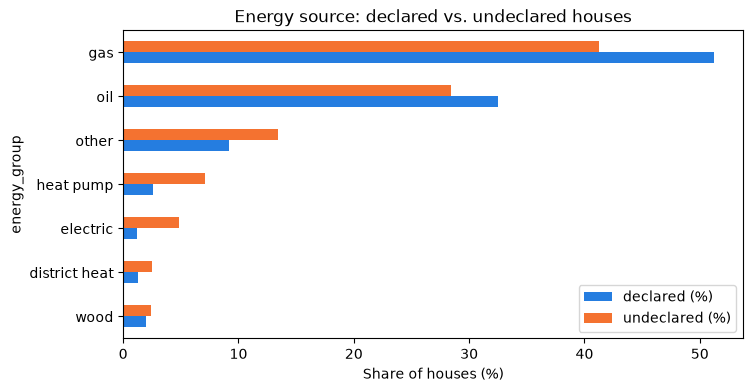

In [9]:
energy = compare("energy_group").sort_values("undeclared (%)")
energy[["declared (%)", "undeclared (%)"]].plot.barh(figsize=(8, 4), color=["#257de0", "#f47230"])
plt.xlabel("Share of houses (%)")
plt.title("Energy source: declared vs. undeclared houses")
plt.savefig(FIGURES / "describe_energy_declared_vs_undeclared.png", dpi=150, bbox_inches="tight")
plt.show()

The orange bars (undeclared) are longer for heat pump, electric and other, and shorter for gas and oil.
Undeclared houses are less often heated with gas or oil and more often with heat pumps or electricity (12% vs. 4%), heating types that are rare in our training data.

## 9. Conclusion

The undeclared houses look like the declared ones in age and size, which are the main drivers of the heating index. They differ in energy source: they use heat pumps and electric heating more often (12% vs. 4%), and the model has seen very few of these. Its predictions for such houses are less reliable, and since these houses tend to have low heating indices, the share of problem houses among the undeclared houses is probably lower than the 38% in our data. We report this as a limitation.